In [ ]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

In [2]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
from skimage.feature import peak_local_max

In [8]:
image = cv.imread('periodic_noise.jpg')
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

In [37]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
dft = cv.dft(np.float32(image_gray), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
rows, cols = image_gray.shape
x, y = np.meshgrid(np.arange(cols), np.arange(rows))
sigma = 30
gauss_mask = np.exp(-((x - cols//2)**2 + (y - rows//2)**2) / (2 * sigma**2))
high_pass_mask = 1 - gauss_mask
dft_shift_hp = dft_shift * high_pass_mask[:, :, np.newaxis]
filtering_magn_res = 20 * np.log(cv.magnitude(dft_shift_hp[:, :, 0], dft_shift_hp[:, :, 1]) + 1)
f_ishift = np.fft.ifftshift(dft_shift_hp)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:, :, 0], img_back[:, :, 1])
highpass_result = cv.normalize(img_back, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)



(np.float64(-0.5), np.float64(786.5), np.float64(593.5), np.float64(-0.5))

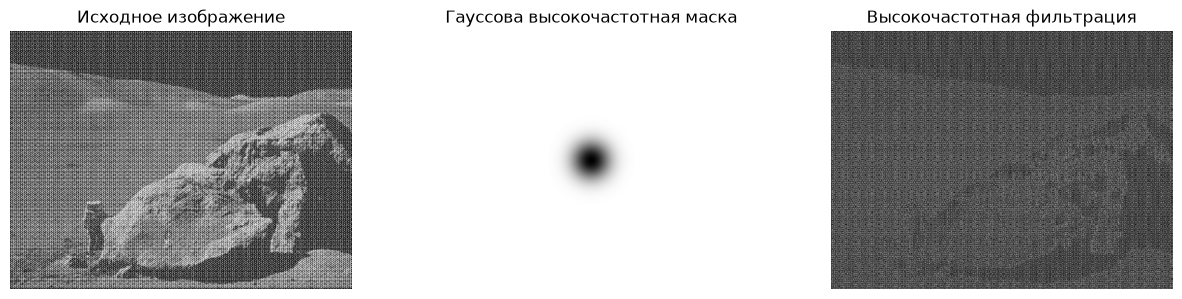

In [36]:
plt.figure(figsize=(15, 5))
plt.subplot(131)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(132)
plt.imshow(high_pass_mask, cmap='gray')
plt.title('Гауссова высокочастотная маска')
plt.axis('off')

plt.subplot(133)
plt.imshow(highpass_result, cmap='gray')
plt.title('Высокочастотная фильтрация')
plt.axis('off')

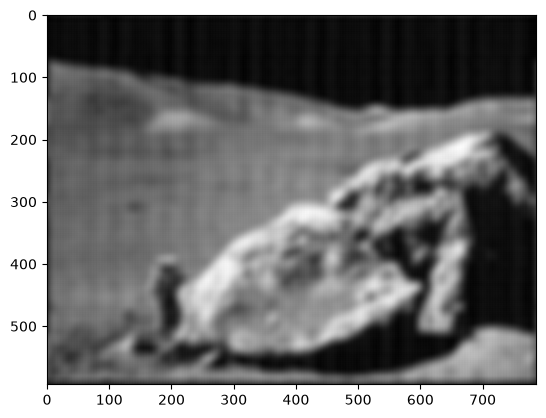

In [ ]:
# Реализуйте вычисление свертки с помощью преобразования Фурье
kernel_size = 25
sigma = 7.0
kernel_1d = cv.getGaussianKernel(kernel_size, sigma)
kernel_2d = np.outer(kernel_1d, kernel_1d)
rows, cols = image_gray.shape
kh, kw = kernel_2d.shape
kernel = np.zeros((rows, cols), dtype=np.float32)
kernel[:kh, :kw] = kernel_2d
kernel = np.roll(kernel, -(kh // 2), axis=0)
kernel = np.roll(kernel, -(kw // 2), axis=1)
dft_img = np.fft.fft2(np.float32(image_gray))
dft_kernel = np.fft.fft2(kernel)
filtered = np.real(np.fft.ifft2(dft_img * dft_kernel))
result = cv.normalize(filtered, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)


plt.imshow(result, cmap='gray')

In [39]:

dft = cv.dft(np.float32(image_gray), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)
# Поиск локальных максимумов
local_max = peak_local_max(
    magnitude_spectrum,
    min_distance=15,
    threshold_abs=200
)
rows, cols = image_gray.shape
mask = np.ones((rows, cols, 2), dtype=np.float32)
center_x, center_y = rows // 2, cols // 2
for peak in local_max:
    y, x = peak

    distance = np.sqrt((x - center_y)**2 + (y - center_x)**2)

    if distance > 40:
        cv.circle(mask, (x, y), 5, (0, 0), -1)
        cv.circle(mask, (cols - x, rows - y), 5, (0, 0), -1)
dft_filtered = dft_shift * mask
filtered_spectrum = 20 * np.log(cv.magnitude(dft_filtered[:, :, 0], dft_filtered[:, :, 1]) + 1)
f_ishift = np.fft.ifftshift(dft_filtered)
image_back = cv.idft(f_ishift)
image_back = cv.magnitude(image_back[:, :, 0], image_back[:, :, 1])

result = cv.normalize(image_back, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

(np.float64(-0.5), np.float64(786.5), np.float64(593.5), np.float64(-0.5))

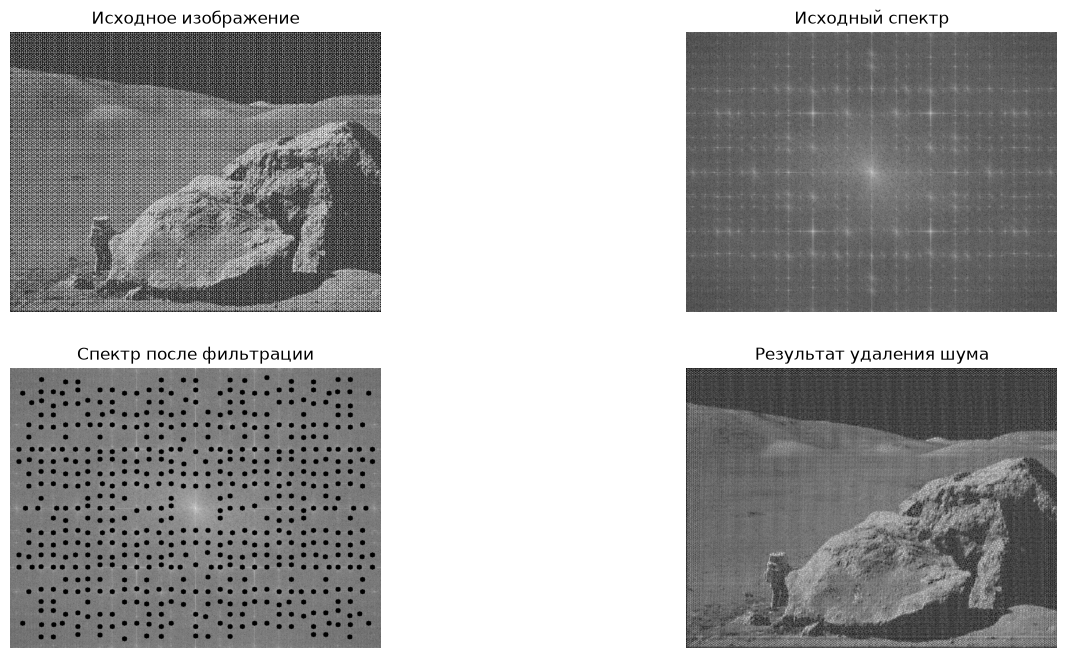

In [ ]:
plt.figure(figsize=(16, 4))

plt.subplot(221)
plt.imshow(image_gray, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(222)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Исходный спектр')
plt.axis('off')

plt.subplot(223)
plt.imshow(filtered_spectrum, cmap='gray')
plt.title('Спектр после фильтрации')
plt.axis('off')

plt.subplot(224)
plt.imshow(result, cmap='gray')
plt.title('Результат удаления шума')
plt.axis('off')